# C3. Pilot on ibm_fez

The Credits form requires that you have tested the idea on the Open Plan and estimated the time from it.
This notebook does both in about 2 minutes of QPU time and writes the three numbers the form asks for.

**As set, Run All submits to ibm_fez** through the account saved on this computer as `Faryad-free-ibm`.
It uses 156 qubits and about 2 minutes of Open Plan time. It stops before submitting if the estimate is above
`MAX_MINUTES`.

- To try it on the laptop first, set `USE_HARDWARE = False`. That uses FakeFez on 10 qubits and submits nothing to IBM.
- To see the cost without submitting, set `SUBMIT = False`.

The 80 tumors go in as three jobs of 10, 20 and 50 tumors. Different job sizes let step C3.7 separate the fixed
cost per job from the cost per shot. Those two numbers drive the budget in C4.

Job ids are saved to `results/jobs/` before anything is awaited. You can close the notebook and come back.
A second run with the same settings does not resubmit.

In [1]:
USE_HARDWARE = True         # True: the real ibm_fez.   False: FakeFez on this laptop (nothing goes to IBM)
SUBMIT       = True         # False: stop after printing the cost in C3.5
MAX_MINUTES  = 5.0          # never submit if the estimate is above this (the Open Plan gives 10 min per 28 days)

ACCOUNT = "Faryad-free-ibm" # saved IBM Quantum account. This IBMid is on your Gmail address (see credits/README.md)
DEVICE  = "ibm_fez"

N_QUBITS  = 156 if USE_HARDWARE else 10      # noisy local simulation is practical up to about 14 qubits
REPS      = 2
BANDWIDTH = 0.25                             # the value the application fixes for the main study
FMAP      = "zz"
JOB_SIZES = [10, 20, 50]                     # tumors per job; keep them unequal
SHOTS     = 1024 if USE_HARDWARE else 256    # per measurement basis
SEED      = 0

TAG = f"pilot_{FMAP}_n{N_QUBITS}_r{REPS}_bw{BANDWIDTH}_{sum(JOB_SIZES)}t_{SHOTS}sh_{'fez' if USE_HARDWARE else 'local'}"
print(TAG)

pilot_zz_n156_r2_bw0.25_80t_1024sh_fez


In [2]:
import os, sys, json, time, math, warnings
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)
OUT = ROOT / "credits" / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
pd.set_option("display.width", 200)
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import EstimatorV2

from pqk100.backends import local_backend
from pqk100.featuremap import FEATURE_MAPS, cone_stats
from pqk100.hardware import build, circuit_report, estimate_minutes
from pqk100.lattice import patch
from pqk100.lightcone import projections
from pqk100.prep import to_angles

class Stop(Exception):
    """Halts 'Run All' with a one-line message instead of a traceback."""
    def _render_traceback_(self):
        return [f"STOPPED: {self}"]

JOBS = ROOT / "results" / "jobs"; JOBS.mkdir(parents=True, exist_ok=True)

project folder: D:\Active Research Projects\PQK100


## C3.1 Tumors

Half from the measured TCGA tumors, half from METABRIC, all from the fixed panel of C1. The genes are the top
`N_QUBITS` of the panel. Labels are not used: the pilot measures cost and signal, not accuracy.

In [3]:
z = np.load(OUT / "fixed_panel.npz", allow_pickle=True)
rng = np.random.default_rng(SEED)
n_tot = sum(JOB_SIZES)
it = np.sort(rng.choice(len(z["y_tcga"]), n_tot // 2, replace=False))
im = np.sort(rng.choice(len(z["y_meta"]), n_tot - n_tot // 2, replace=False))
Z = np.vstack([z["Z_tcga"][it], z["Z_meta"][im]])[:, :N_QUBITS].astype(np.float64)
angles = to_angles(Z, BANDWIDTH)
ids = list(z["ids_tcga"][it]) + list(z["ids_meta"][im])
print(f"{len(angles)} tumors ({len(it)} TCGA, {len(im)} METABRIC), {angles.shape[1]} angles each")

80 tumors (40 TCGA, 40 METABRIC), 156 angles each


## C3.2 Backend

In [4]:
if USE_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    saved = list(QiskitRuntimeService.saved_accounts())          # names only; the API key is never printed
    if ACCOUNT not in saved:
        raise Stop(f"no saved account named {ACCOUNT!r} on this computer. Saved accounts: {saved or 'none'}. "
                   "Save it once with QiskitRuntimeService.save_account(token=..., name=ACCOUNT, channel='ibm_quantum_platform').")
    service = QiskitRuntimeService(name=ACCOUNT)
    try:
        backend = service.backend(DEVICE)
    except Exception as e:
        names = [b.name for b in service.backends()]
        raise Stop(f"{DEVICE} is not available to {ACCOUNT} ({type(e).__name__}). Available: {names}")
    st = backend.status()
    print(f"{backend.name}: {backend.num_qubits} qubits, operational={st.operational}, pending jobs={st.pending_jobs}")
    try:
        print("account usage:", service.usage())
    except Exception as e:
        print("usage not available from this client:", type(e).__name__)
else:
    service, backend = None, local_backend()
    print(f"{backend.name}: {backend.num_qubits} qubits (local noise model)")

ibm_fez: 156 qubits, operational=True, pending jobs=0
account usage: {'instance_id': 'crn:v1:bluemix:public:quantum-computing:us-east:a/2f903a94d6564bb2a042b9d46bda122d:942366bb-691a-4716-b061-b6860eece7f3::', 'plan_id': '850b21a7-71de-4e53-9441-1abdd202f35d', 'usage_consumed_seconds': 7770, 'usage_consumed_ru': 126.826814, 'usage_period': {'start_time': '2026-03-30T08:48:26.888Z', 'end_time': '2027-03-30T08:48:26.888Z'}, 'usage_limit_seconds': 10800, 'usage_limit_ru': 180, 'usage_allocation_seconds': 10800, 'usage_allocation_ru': 180, 'usage_limit_reached': False, 'usage_remaining_seconds': 3030}


## C3.3 Patch and circuit

The patch uses today's calibration, so it can differ between runs. It is saved with the job ids.
The circuit is transpiled once; every tumor is one row of parameter values.

In [5]:
job_file = JOBS / f"{TAG}.json"
if USE_HARDWARE and job_file.exists():                # reopened later: use the patch the jobs actually ran on
    record = json.loads(job_file.read_text())
    phys = record["phys"]
    loc = {q: i for i, q in enumerate(phys)}
    edges = sorted({tuple(sorted((loc[a], loc[b]))) for a, b in backend.coupling_map.get_edges() if a in loc and b in loc})
    print("using the patch saved with the submitted jobs")
else:
    phys, edges = patch(backend, N_QUBITS)
ops = FEATURE_MAPS[FMAP](N_QUBITS, edges, reps=REPS)
isa, cols, observables = build(N_QUBITS, ops, phys, backend)
values = angles[:, cols]
rep = circuit_report(isa, backend)

t = backend.target; inside = set(phys)
cz = np.array([p.error for qs, p in t["cz"].items() if qs[0] in inside and qs[1] in inside and p is not None and p.error is not None])
print(f"patch: {len(phys)} qubits, {len(edges)} couplers, median CZ error {np.median(cz):.4f}")
print(f"circuit: {rep['twoq_gates']} CZ gates after transpilation, CZ depth {rep['twoq_depth']}, {rep['circuit_s'] * 1e6:.1f} us long")

using the patch saved with the submitted jobs
patch: 156 qubits, 176 couplers, median CZ error 0.0026
circuit: 704 CZ gates after transpilation, CZ depth 12, 1.4 us long


## C3.4 Exact reference

In [6]:
size, n2q, ncz = cone_stats(N_QUBITS, ops)
exact = projections(N_QUBITS, ops, angles)[0]
print(f"largest light cone: {size.max()} qubits, up to {ncz.max()} CZ gates in a cone")

largest light cone: 7 qubits, up to 18 CZ gates in a cone


## C3.5 Cost

Two estimates. IBM's quick formula is 2 s per job plus 0.35 ms per execution (circuit × shot).
The repository's estimate uses the shot length from the calibration data with a 1.5x allowance.

In [7]:
bounds = np.cumsum([0] + JOB_SIZES); bounds[-1] = len(values)
bounds = list(zip(bounds[:-1], bounds[1:]))
execs = len(values) * 3 * SHOTS
ibm_quick = 2.0 * len(bounds) + 0.00035 * execs
repo_est = estimate_minutes(rep, len(values), SHOTS) * 60
print(f"{len(values)} tumors x 3 bases x {SHOTS} shots = {execs:,} executions in {len(bounds)} jobs")
print(f"IBM quick formula : {ibm_quick:5.0f} s = {ibm_quick / 60:.1f} min")
print(f"repository        : {repo_est:5.0f} s = {repo_est / 60:.1f} min")
print("The Open Plan gives 10 min per 28 days.")

80 tumors x 3 bases x 1024 shots = 245,760 executions in 3 jobs
IBM quick formula :    92 s = 1.5 min
repository        :    93 s = 1.6 min
The Open Plan gives 10 min per 28 days.


## C3.6 Submit

In [8]:
estimator = EstimatorV2(mode=backend)
estimator.options.default_shots = SHOTS
if USE_HARDWARE:                                    # readout mitigation only (TREX); no ZNE, no gate twirling
    estimator.options.resilience_level = 1
    estimator.options.resilience.measure_mitigation = True
    estimator.options.resilience.zne_mitigation = False
    estimator.options.twirling.enable_measure = True
    estimator.options.twirling.enable_gates = False
    estimator.options.dynamical_decoupling.enable = False

est_min = max(ibm_quick, repo_est) / 60
if USE_HARDWARE and job_file.exists():
    print(f"Already submitted on {record['created']}: {len(record['jobs'])} jobs. Not submitting again.")
    jobs = [service.job(j["id"]) for j in record["jobs"]]
elif USE_HARDWARE and not SUBMIT:
    raise Stop(f"nothing submitted. Estimated cost about {est_min:.1f} min. Set SUBMIT = True in the first cell and run again.")
elif USE_HARDWARE and est_min > MAX_MINUTES:
    raise Stop(f"nothing submitted. The estimate ({est_min:.1f} min) is above MAX_MINUTES = {MAX_MINUTES}.")
else:
    record = {"tag": TAG, "backend": backend.name, "account": ACCOUNT if USE_HARDWARE else None,
              "created": time.strftime("%Y-%m-%d %H:%M:%S"), "shots": SHOTS, "phys": [int(q) for q in phys],
              "tumors": [str(s) for s in ids], "jobs": []}
    jobs = []
    for a, b in bounds:
        job = estimator.run([(isa, observables, values[a:b])])
        jobs.append(job)
        record["jobs"].append({"id": job.job_id(), "start": int(a), "stop": int(b)})
        if USE_HARDWARE:
            job_file.write_text(json.dumps(record, indent=1))      # saved after every submission
    np.save(JOBS / f"{TAG}_angles.npy", angles)
    print(f"submitted {len(jobs)} jobs" + (f"; ids in {job_file}" if USE_HARDWARE else " to the local simulator"))

Already submitted on 2026-10-18 07:33:19: 3 jobs. Not submitting again.


## C3.7 Collect and measure the true cost

Run this cell again later if the jobs are still queued. The fit is

`billed seconds per job = overhead + (rate per shot) × (tumors × 3 × shots)`

In [9]:
if USE_HARDWARE:
    states = [str(j.status()) for j in jobs]
    print(pd.Series(states).value_counts().to_string())
    if any(s in ("ERROR", "CANCELLED") for s in states):
        raise Stop("a job failed or was cancelled. Check it on the IBM Quantum dashboard; delete " + str(job_file) + " to start over.")
    if any(s != "DONE" for s in states):
        raise Stop("jobs are not finished yet. Run this cell again later.")

P_dev, P_err = [], []
for job in jobs:
    data = job.result()[0].data
    P_dev.append(np.asarray(data.evs).reshape(3, N_QUBITS, -1).transpose(2, 0, 1))     # (tumors, 3, qubits)
    P_err.append(np.asarray(data.stds).reshape(3, N_QUBITS, -1).transpose(2, 0, 1))
P_dev, P_err = np.concatenate(P_dev), np.concatenate(P_err)
np.save(JOBS / f"{TAG}_projections.npy", P_dev)

usage = []
for j in jobs:
    try:
        usage.append(float(j.usage()))
    except Exception:
        usage.append(float("nan"))
usage = np.array(usage)
ex = np.array([(b - a) * 3 * SHOTS for a, b in bounds], dtype=float)

us_per_shot = overhead_s = None
if np.all(np.isfinite(usage)) and usage.sum() > 0:
    us_simple = usage.sum() / ex.sum() * 1e6
    (a0, b0), *_ = np.linalg.lstsq(np.vstack([np.ones_like(ex), ex]).T, usage, rcond=None)
    if b0 > 0 and a0 >= 0:
        us_per_shot, overhead_s = b0 * 1e6, a0
    else:                                          # the fit is not usable (rounding on small jobs); fall back
        us_per_shot, overhead_s = us_simple, 0.0
    print(pd.DataFrame({"tumors": [b - a for a, b in bounds], "executions": ex.astype(int), "billed s": usage}).to_string(index=False))
    print(f"\ntotal billed: {usage.sum():.0f} s = {usage.sum() / 60:.2f} min  (IBM quick formula said {ibm_quick:.0f} s)")
    print(f"fit: {overhead_s:.1f} s per job + {us_per_shot:.0f} us per shot   (all-in average: {us_simple:.0f} us per shot)")
else:
    print("billed time not reported (normal for the local simulator)")

DONE    3
 tumors  executions  billed s
     10       30720      20.0
     20       61440      29.0
     50      153600      55.0

total billed: 104 s = 1.73 min  (IBM quick formula said 92 s)
fit: 11.4 s per job + 284 us per shot   (all-in average: 423 us per shot)


## C3.8 Device against exact

**Signal retained** per qubit is the slope of measured against exact values, over all tumors and the three Paulis.
**Feature correlation** looks only at how each feature varies across tumors, after removing its mean. At bandwidth 0.25
the features vary little, so this second number is the stricter test of whether the data survived the noise.

correlation with exact values      : 0.9316
signal retained per qubit          : mean 0.889, median 0.950, worst -0.463
gate-error-only expectation        : median 0.960
feature correlation across tumors  : median 0.913  (468 features that vary)
median shot standard error         : 0.0275


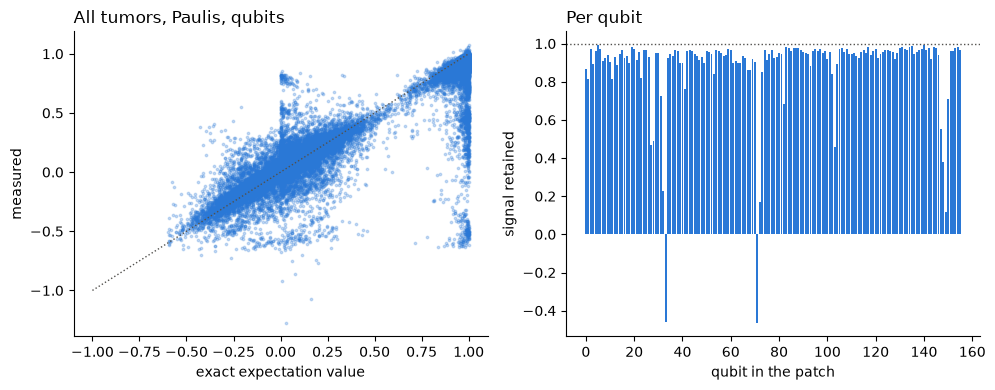

In [10]:
keep = (P_dev * exact).sum((0, 1)) / (exact ** 2).sum((0, 1))
r_all = float(np.corrcoef(P_dev.ravel(), exact.ravel())[0, 1])
Ed, Ee = (P_dev - P_dev.mean(0)).reshape(len(P_dev), -1), (exact - exact.mean(0)).reshape(len(exact), -1)
ok = Ee.std(0) > 1e-3
fcorr = (Ed[:, ok] * Ee[:, ok]).sum(0) / np.sqrt((Ed[:, ok] ** 2).sum(0) * (Ee[:, ok] ** 2).sum(0))
eps = float(np.median(cz))

print(f"correlation with exact values      : {r_all:.4f}")
print(f"signal retained per qubit          : mean {keep.mean():.3f}, median {np.median(keep):.3f}, worst {keep.min():.3f}")
print(f"gate-error-only expectation        : median {np.median((1 - eps) ** ncz):.3f}")
print(f"feature correlation across tumors  : median {np.median(fcorr):.3f}  ({ok.sum()} features that vary)")
print(f"median shot standard error         : {np.median(P_err):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot([-1, 1], [-1, 1], color="#52514e", lw=1, ls=":")
ax[0].scatter(exact.ravel(), P_dev.ravel(), s=3, alpha=0.25, color="#2a78d6", rasterized=True)
ax[0].set_xlabel("exact expectation value"); ax[0].set_ylabel("measured"); ax[0].set_title("All tumors, Paulis, qubits", loc="left")
ax[1].bar(np.arange(N_QUBITS), keep, color="#2a78d6", width=0.8)
ax[1].axhline(1.0, color="#52514e", lw=1, ls=":")
ax[1].set_xlabel("qubit in the patch"); ax[1].set_ylabel("signal retained"); ax[1].set_title("Per qubit", loc="left")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / f"{TAG}.png", dpi=160)

## C3.9 Summary for the form

In [11]:
summary = {
    "mode": "hardware" if USE_HARDWARE else "local", "backend": backend.name, "date": time.strftime("%Y-%m-%d"),
    "qubits": N_QUBITS, "reps": REPS, "bandwidth": BANDWIDTH, "cz_gates": rep["twoq_gates"], "cz_depth": rep["twoq_depth"],
    "shots": SHOTS, "tumors": len(values), "job_sizes": JOB_SIZES,
    "billed_s_per_job": [None if not np.isfinite(u) else float(u) for u in usage],
    "billed_s_total": float(np.nansum(usage)) if np.isfinite(usage).any() else None,
    "us_per_shot": us_per_shot, "overhead_s_per_job": overhead_s,
    "signal_retained_mean": float(keep.mean()), "signal_retained_median": float(np.median(keep)),
    "signal_retained_worst": float(keep.min()), "correlation": r_all, "feature_corr_median": float(np.median(fcorr)),
    "median_cz_error": eps, "phys": [int(q) for q in phys], "tag": TAG,
}
name = "pilot_summary.json" if USE_HARDWARE else "pilot_summary_local.json"
(OUT / name).write_text(json.dumps(summary, indent=1))
print("wrote", OUT / name)

where = "ibm_fez" if USE_HARDWARE else "FakeFez (local test, not for the form)"
rate = f"{us_per_shot:.0f} \u00b5s billed per shot" if us_per_shot else "[billed time per shot not available]"
print(f"\nPilot on {where}: {N_QUBITS} qubits, {rate}, {100 * keep.mean():.0f}% of the exact signal retained on average across qubits.")

wrote D:\Active Research Projects\PQK100\credits\outputs\pilot_summary.json

Pilot on ibm_fez: 156 qubits, 284 µs billed per shot, 89% of the exact signal retained on average across qubits.
